#### **Predicting Chronic Kidney Disease from Routine Clinical and Laboratory Data**
---
**Goal:** build a model that classifies a patient as *CKD* or *not CKD* using routine urine, blood and clinical measurements.
**Dataset:** [UCI Chronic Kidney Disease](https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease)(400 patients, 24 features). It was collected at a hospital in Tamil Nadu, India, over about two months in 2015.


#### **Workflow**
----
1. Load the data
2. Clean the data
3. Check class balance and missing values
4. Exploratory data analysis (EDA)
5. Train/test split
6. Preprocessing pipeline
7. Compare three models with cross-validation
8. Tune the selected model
9. Final evaluation on the held-out test set
10. Robustness check, limitations and conclusion
---

**NB : Why recall matters here:** this is a screening-type problem. Missing a real CKD patient (false negative) is worse than flagging a healthy one (false positive), so I report **recall (sensitivity)** alongside ROC-AUC, precision and F1.

#### **Data dictionary**
---

| Column | Meaning | Type |
|---|---|---|
| age | Age (years) | numeric |
| bp | Blood pressure (mm Hg) | numeric |
| sg | Urine specific gravity | numeric |
| al | Urine albumin (0-5) | numeric |
| su | Urine sugar (0-5) | numeric |
| rbc | Red blood cells in urine (normal / abnormal) | categorical |
| pc | Pus cells in urine (normal / abnormal) | categorical |
| pcc | Pus cell clumps (present / notpresent) | categorical |
| ba | Bacteria in urine (present / notpresent) | categorical |
| bgr | Random blood glucose (mg/dL) | numeric |
| bu | Blood urea (mg/dL) | numeric |
| sc | Serum creatinine (mg/dL) | numeric |
| sod | Sodium (mEq/L) | numeric |
| pot | Potassium (mEq/L) | numeric |
| hemo | Haemoglobin (g/dL) | numeric |
| pcv | Packed cell volume | numeric |
| wbcc | White blood cell count (cells/cumm) | numeric |
| rbcc | Red blood cell count (millions/cmm) | numeric |
| htn | Hypertension (yes / no) | categorical |
| dm | Diabetes mellitus (yes / no) | categorical |
| cad | Coronary artery disease (yes / no) | categorical |
| appet | Appetite (good / poor) | categorical |
| pe | Pedal oedema (yes / no) | categorical |
| ane | Anaemia (yes / no) | categorical |
| class | **Target:** ckd / notckd | target |

In [30]:
# Core libraries
import os

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count()) # tells joblib how many cores to use, so it skips the wmic lookup
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# scikit-learn tools
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    roc_auc_score,
)

# scikit-learn tools
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

RANDOM_STATE = 42  # makes every result reproducible
sns.set_theme(style="whitegrid")

#### **1. Load the data**
---
I will first try to download the data directly from the UCI repository. Youo need to install this first(`pip install ucimlrepo`).
If that fails (for example, no internet), it falls back to a local file called `kidney_disease.csv`, that is if you have it on your device:

In [2]:
# i will use a try and exceot block here: You can use any depending on where your data for the model lives:
try:
    from ucimlrepo import fetch_ucirepo

    ckd = fetch_ucirepo(id=336)  # 336 = Chronic Kidney Disease
    df = pd.concat([ckd.data.features, ckd.data.targets], axis=1)
    print("Loaded from the UCI repository")
except (ImportError, OSError):
    df = pd.read_csv("kidney_disease.csv")
    df = df.rename(columns={"classification": "class"}).drop(
        columns="id", errors="ignore"
    )
    print("Loaded from local kidney_disease.csv")

print("Shape:", df.shape)
df.head()

Loaded from the UCI repository
Shape: (400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [3]:
# First look: data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    object 
 21  appet   399 non-null    object 
 22  pe

### **2. Clean the data**
----

I have already checked the data and it is dirty.Typical problems are:
- stray spaces and tabs in text values (e.g.`"\tno"`, `"ckd\t"`)
- missing values written as `"?"`
- numeric columns stored as text because of the problems above

This is what I will do at this stage: 
- strip whitespace, convert `?` to proper missing values, force numeric columns to numbers and 
- Encode the target (**CKD = 1, not CKD = 0**), and drop duplicate rows.

In [4]:
# let's create list of our columns:
numeric_cols = [col for col in df.columns if df[col].dtype != "object"]
print("numeric_columns :", numeric_cols)
print("----" *30)
categorical_cols = [col for col in df.columns if df[col].dtype == "object"]
categorical_cols.remove("class")
print("categorical_columns :",categorical_cols)

numeric_columns : ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
------------------------------------------------------------------------------------------------------------------------
categorical_columns : ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [5]:
# let's create a copy of our dataframe:
df = df.copy()

# 1) Strip whitespace/tabs and turn "?" or empty text into real missing values
for col in df.columns:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].str.strip().replace({"?": np.nan, "": np.nan})

# 2) Make sure numeric columns are numbers (anything unreadable becomes NaN)
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 3) Encode the target: ckd = 1, notckd = 0
df["target"] = df["class"].map({"ckd": 1, "notckd": 0})
# let's use an assert statement to check if the class converstion worked:
assert df["target"].notna().all(), "Unexpected values in the class column"

# dropping the class column after creating the dummy coded one:
df = df.drop(columns="class")

# 4) Remove duplicate rows (if any)
print("Duplicate rows removed:", df.duplicated().sum())
df = df.drop_duplicates()

# 5) Check the categorical columns now have clean, consistent labels
for col in categorical_cols:
    print(f"{col:6s}", df[col].value_counts(dropna=False).to_dict())

Duplicate rows removed: 0
rbc    {'normal': 201, nan: 152, 'abnormal': 47}
pc     {'normal': 259, 'abnormal': 76, nan: 65}
pcc    {'notpresent': 354, 'present': 42, nan: 4}
ba     {'notpresent': 374, 'present': 22, nan: 4}
htn    {'no': 251, 'yes': 147, nan: 2}
dm     {'no': 261, 'yes': 137, nan: 2}
cad    {'no': 364, 'yes': 34, nan: 2}
appet  {'good': 317, 'poor': 82, nan: 1}
pe     {'no': 323, 'yes': 76, nan: 1}
ane    {'no': 339, 'yes': 60, nan: 1}


In [6]:
# Sanity check on numeric ranges: You can see there is a little problem
# Potassium and sodium has some problems: The minimum for sodium(sod) and the maximum for potassium(pot)
# There are no biologically impossible values, zero minimums are allowed for the urine albumin and sugar: 
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,391.0,51.48,17.17,2.0,42.00,55.00,64.50,90.00
bp,388.0,76.47,13.68,50.0,70.00,80.00,80.00,180.00
sg,353.0,1.02,0.01,1.0,1.01,1.02,1.02,1.02
al,354.0,1.02,1.35,0.0,0.00,0.00,2.00,5.00
su,351.0,0.45,1.10,0.0,0.00,0.00,0.00,5.00
bgr,356.0,148.04,79.28,22.0,99.00,121.00,163.00,490.00
bu,381.0,57.43,50.50,1.5,27.00,42.00,66.00,391.00
sc,383.0,3.07,5.74,0.4,0.90,1.30,2.80,76.00
sod,313.0,137.53,10.41,4.5,135.00,138.00,142.00,163.00
pot,312.0,4.63,3.19,2.5,3.80,4.40,4.90,47.00


In [7]:
# let's fix those two columns:
# Only values no living patient could have; These values are quiet incompatible with life
df.loc[df["pot"] > 20, "pot"] = np.nan  # K+ of 39 and 47 mmol/L
df.loc[df["sod"] < 50, "sod"] = np.nan  # Na+ of ~4.5 mEq/L
# serum creatinine is left untouched; I am not sure, cause some clients with CKD can have extremely high creatinine values

#### **3. Class balance and missing values**
---
Two checks before modelling:

- **Class balance:** if one class dominates too much, accuracy becomes misleading.
- **Missing values:** tells us how much imputation we rely on, and which columns are most affected.

target
CKD        250
Not CKD    150
Name: count, dtype: int64
target
CKD        62.5 %
Not CKD    37.5 %
Name: count, dtype: object


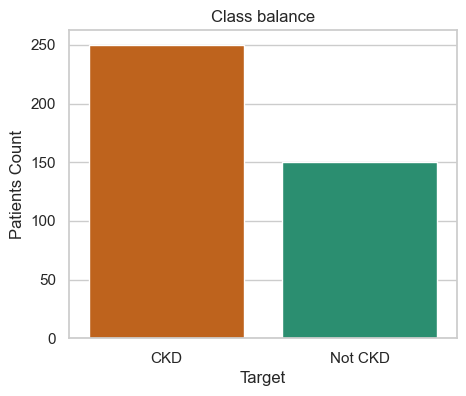

In [8]:
# Class balance
counts = df["target"].value_counts().rename({1: "CKD", 0: "Not CKD"})
print(counts)
# let's make it percentages, you could use normalize = True but i like it this way. flexing my maths small
print((counts / len(df) * 100).round(1).astype(str) + " %")

#let's plot a barchart
plt.figure(figsize=(5,4))
sns.barplot(
    x=counts.index, 
    y=counts.values, 
    hue=counts.index, 
    palette=["#d95f02", "#1b9e77"],
    legend=False
)
plt.title("Class balance")
plt.ylabel("Patients Count")
plt.xlabel("Target")
plt.show()

##### **Missing Values:**
---

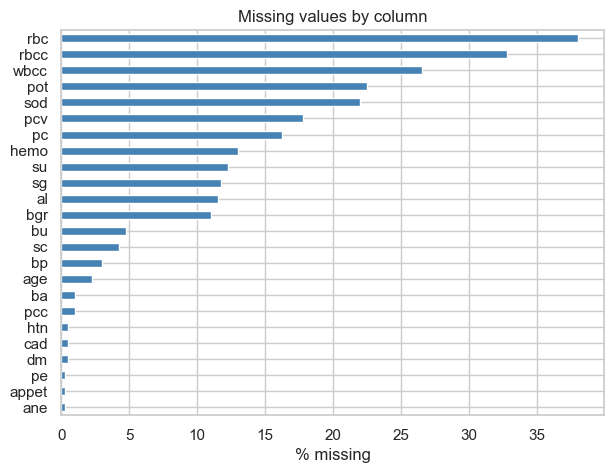

Rows with at least one missing value: 61%


In [9]:
# Missing values per column
missing_pct = (df.drop(columns="target").isna().mean() * 100).sort_values(ascending=True)
missing_pct = missing_pct[missing_pct > 0]

# plotting missing vlaues by column
plt.figure(figsize=(7, 5))
missing_pct.plot(kind="barh", color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values by column")
#plt.gca().invert_yaxis()
plt.show()

# checking percentage of rows with atleast a missing value:
print("Rows with at least one missing value:", f"{df.isna().any(axis=1).mean() * 100:.0f}%")

**What this tells us**

- The classes are moderately imbalanced (roughly 60/40), not extreme. I will handle this with `class_weight="balanced"` and by reporting recall, precision and ROC-AUC rather than accuracy alone.
- Many columns have missing values, and most rows are missing at least one. Dropping incomplete rows would throw away most of a small dataset, so I **impute inside the modelling pipeline** instead (this also prevents data leakage).
- Please, keep in mind that sometimes i use mean to determine proportion and that works when the variable has, two levels and coded strictly as 0 and 1. or it has True or False values which evalues to 0 and 1 numerically.
- If your variables don't have this level, use other methods like `value_counts(normalize = True)` and others to achieve thi.

#### **4. Exploratory data analysis**
---
I will first compare each feature between CKD and non-CKD patients.

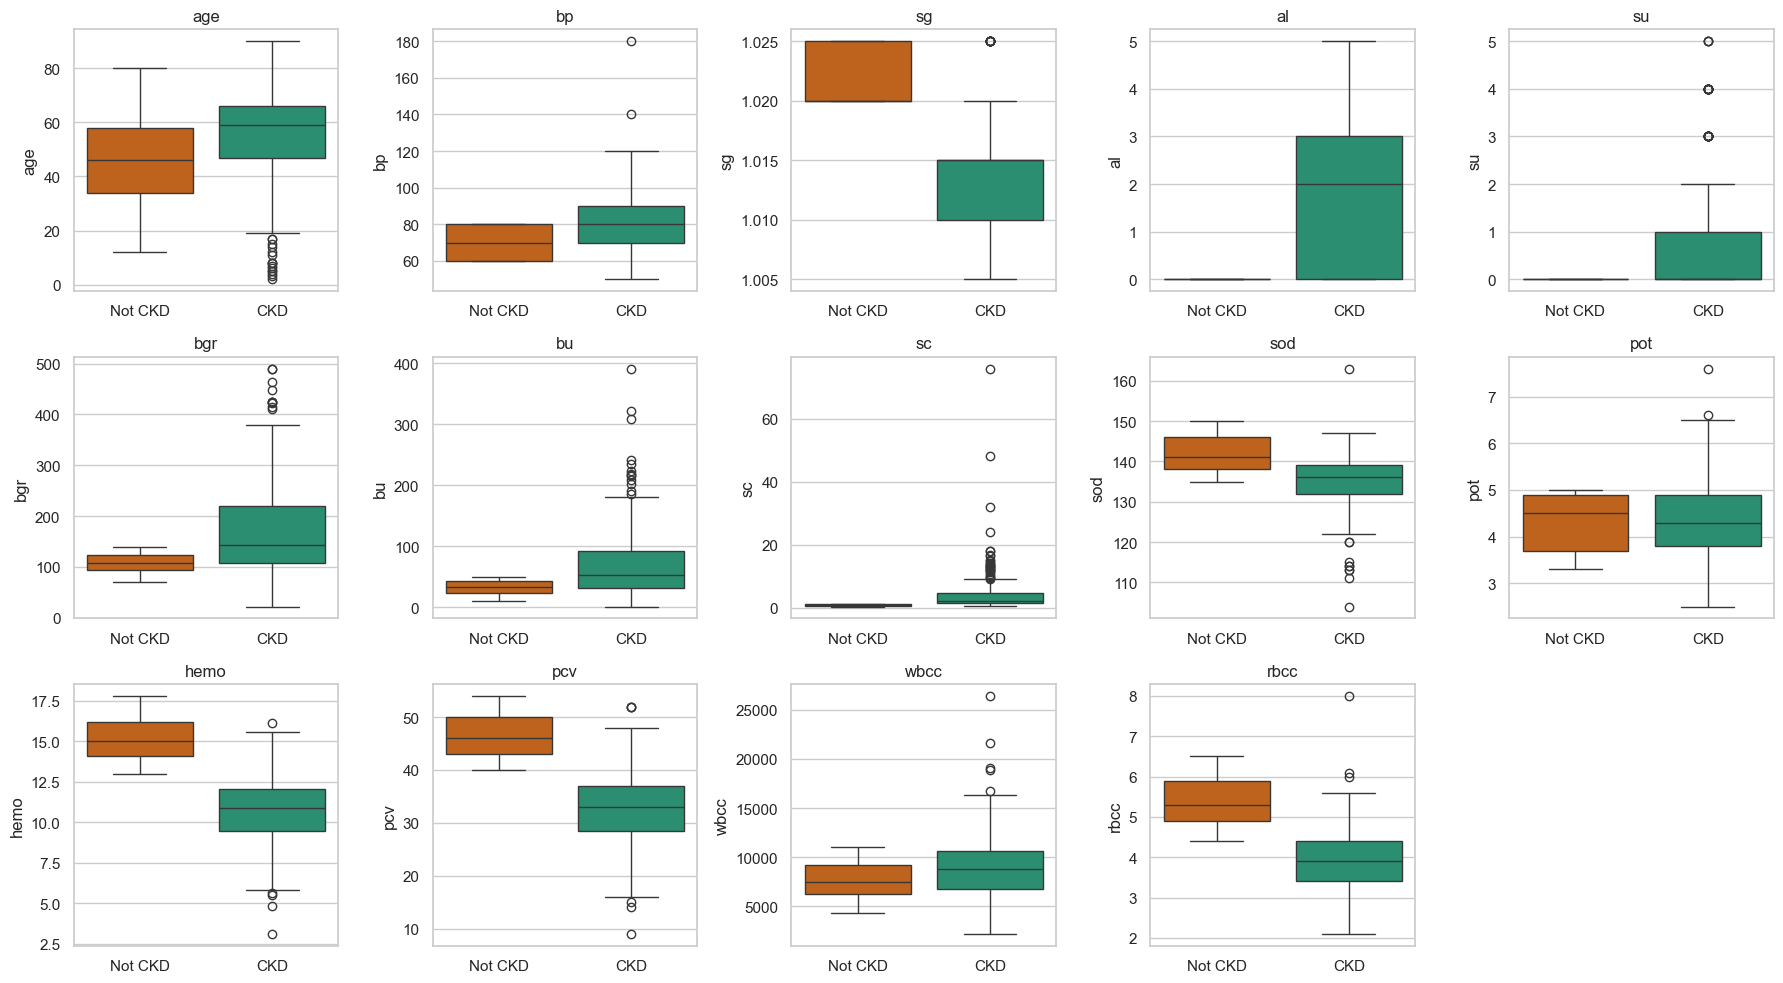

In [10]:
# Numeric features: distribution by diagnosis/target
plot_df = df.assign(diagnosis=df["target"].map({0: "Not CKD", 1: "CKD"}))

fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=plot_df, x="diagnosis", y=col, order=["Not CKD", "CKD"],
                hue="diagnosis", palette=["#1b9e77", "#d95f02"], legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")  # the plot is neat without the xlabel, i think i like it this way
axes.flat[-1].axis("off")      # 14 plots in a 15-slot grid, that is how you remove the last one
plt.tight_layout()
plt.show()

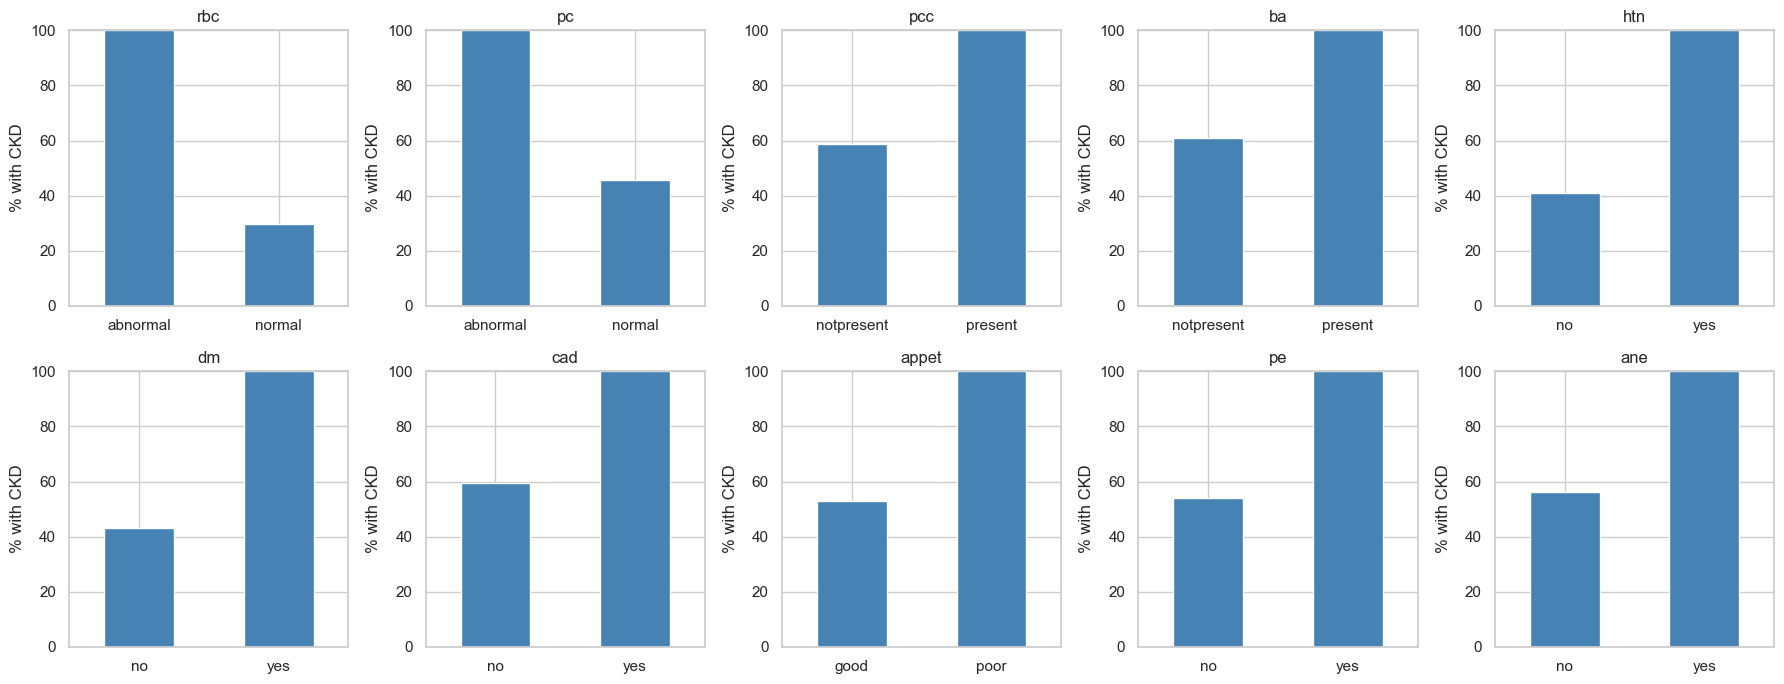

In [28]:
# Categorical features: percentage of patients with CKD in each category
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, categorical_cols):
    rate = df.groupby(col)["target"].mean() * 100  #calculate proportion of CKD in each category
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("% with CKD")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

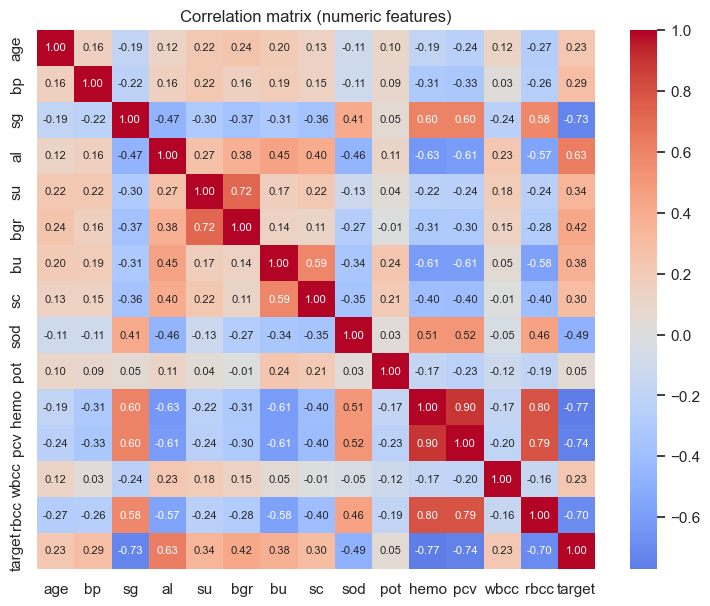

In [12]:
# Correlation between numeric features and the target
corr = df[numeric_cols + ["target"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation matrix (numeric features)")
plt.show()

#### **Key Findings from the EDA**
---
- CKD patients tend to show **lower haemoglobin, packed cell volume and red cell count** (anaemia of CKD) and **higher serum creatinine and blood urea** (reduced filtration).
- **Urine albumin** is higher and **specific gravity** is lower in CKD (damaged kidneys leak protein and concentrate urine poorly).
- Hypertension, diabetes, pedal oedema, anaemia and poor appetite are all more common in the CKD group.
- Several features are strongly correlated with each other (e.g. haemoglobin, PCV and RBC count). That is fine for tree models and regularised logistic regression, but it means individual coefficients should not be over-interpreted.

#### **5. Train/test split**
---
- I hold out 20% of patients as a **test set that is touched only once, at the very end**.
- The split is *stratified* so both sets keep the same CKD proportion.
- All model comparison and tuning uses the training set only.

In [15]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| CKD share:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  "| CKD share:", round(y_test.mean(), 3))

Train: (320, 24) | CKD share: 0.625
Test:  (80, 24) | CKD share: 0.625


#### **6. Preprocessing pipeline**
---

Using scikit-learn pipelines keeps preprocessing and modelling together, so imputation and scaling are **learned from the training folds only** (no data leakage).

| Feature type | Steps |
|---|---|
| Numeric | fill missing with the **median**, then **standardise** |
| Categorical | fill missing with the **most frequent** category, then **one-hot encode** |

In [17]:
numeric_pipe = make_pipeline(SimpleImputer(strategy="median"), RobustScaler())
categorical_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"),
                                 OneHotEncoder(handle_unknown="ignore"))

preprocessor = make_column_transformer(
    (numeric_pipe, numeric_cols),
    (categorical_pipe, categorical_cols),
)
preprocessor

ColumnTransformer(transformers=[('pipeline-1',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('robustscaler',
                                                  RobustScaler())]),
                                 ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu',
                                  'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc',
                                  'rbcc']),
                                ('pipeline-2',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad',
                                  'appet', 'pe', 'ane'])])

##### **6.1 One More thing, Let's look at Multicolinearity**
---
- This might not matter for the randomFrorest classifier and the gradient boosting models
- It matters for regression especially if you want interpretation and not just prediction

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Impute and scale using the training set only (same steps as the pipeline)
X_num = clone(numeric_pipe).fit_transform(X_train[numeric_cols])

vif = pd.Series(
    [variance_inflation_factor(X_num, i) for i in range(X_num.shape[1])],
    index=numeric_cols,
).sort_values(ascending=False)
# showing vif greater than 1.5
vif[vif>1.5].round(1)

pcv     4.5
hemo    3.9
rbcc    2.3
bu      2.2
al      2.0
sg      1.9
su      1.8
bgr     1.7
sc      1.5
dtype: float64

In [ ]:
## Le't Repeat the VIF on the unimputed features:
complete = X_train[numeric_cols].dropna()
X_cc = StandardScaler().fit_transform(complete)
vif_cc = pd.Series(
    [variance_inflation_factor(X_cc, i) for i in range(X_cc.shape[1])],
    index=numeric_cols,
).sort_values(ascending=False)
# filtering vif greater than 1.5
vif_cc[vif_cc > 1.5].round(1)

hemo    5.4
pcv     5.3
sc      4.8
bu      4.5
rbcc    3.4
al      3.1
su      2.7
bgr     2.7
sg      2.4
sod     1.8
dtype: float64

##### **6.2 Findings From VIF**
---
- VIF was computed on the training set both after median imputation (maximum 4.5) and on complete cases only (maximum 5.4, for hemoglobin).
- Imputation pulls values towards the median and weakens correlations, so the true value is likely nearer the upper figure.
- Hemoglobin, PCV and RBC count are physiologically related (PCV/HCT ≈ 3 × Hb through MCHC; Hb and RBC through MCH), so moderate collinearity is expected.
- Because the goal of this project is prediction and the chosen models tolerate correlated inputs, all features were retained. 
- Also lot's of biochemical parameters such as blood urea and creatinine, blood glucose and urine sugar, etc move together.
- Dropping the redundant red-cell variables will be tested separately later in the notebook.

### **7. Compare three models**
---

| Model | Why include it |
|---|---|
| **Logistic Regression** | Simple, fast, interpretable baseline |
| **Random Forest** | Handles non-linear patterns and interactions, robust on small data |
| **Gradient Boosting** | Often the strongest tabular model |

Each model is evaluated with **5-fold stratified cross-validation repeated 3 times** on the training set (15 scores per model),
which gives a more stable estimate than a single split on a small dataset.

In [91]:
models = {
    "Logistic Regression": make_pipeline(
        preprocessor,
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(
        preprocessor,
        RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE)),
    "Gradient Boosting": make_pipeline(
        preprocessor,
        HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = ["roc_auc", "recall", "precision", "f1", "accuracy"]

cv_scores = {}
for name, model in models.items():
    cv_scores[name] = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)

# Average each metric across the 15 folds
results = pd.DataFrame({
    name: {metric: scores[f"test_{metric}"].mean() for metric in scoring}
    for name, scores in cv_scores.items()
}).T
results["roc_auc_std"] = [cv_scores[n]["test_roc_auc"].std() for n in results.index]

results = results.sort_values(["roc_auc", "recall"], ascending=False).round(3)
results

,roc_auc,recall,precision,f1,accuracy,roc_auc_std
Logistic Regression,1.000,0.985,1.000,0.992,0.991,0.000
Gradient Boosting,1.000,0.990,0.997,0.993,0.992,0.001
Random Forest,0.999,0.998,0.990,0.994,0.993,0.001


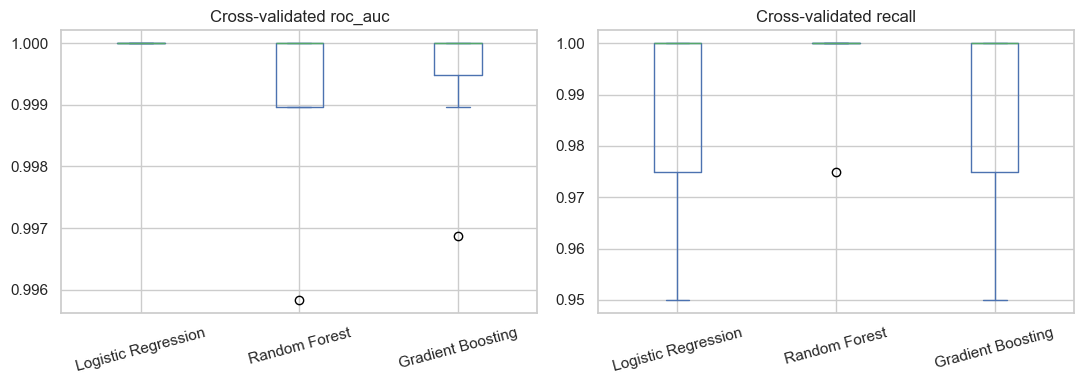

In [34]:
# Visual comparison of the spread across folds
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["roc_auc", "recall"]):
    pd.DataFrame({n: s[f"test_{metric}"] for n, s in cv_scores.items()}).plot(kind="box", ax=ax)
    ax.set_title(f"Cross-validated {metric}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [95]:
# Select the model with the best ROC-AUC (recall breaks ties).
# Good practice: if two models are within one standard deviation of each other,
# prefer the simpler one.
best_name = results.index[2]
print("Selected model:", best_name)

Selected model: Random Forest


**Model selection rule:** highest cross-validated ROC-AUC, with recall as the tie-breaker.
On a clean, small dataset like this one several models can score almost identically, so differences smaller than the fold-to-fold spread (`roc_auc_std`) should not be over-interpreted.
ROC-AUC was saturated (0.999 to 1.000) across all three models and could not discriminate between them. Because missing a CKD patient costs clinically more in a screening setting, the models were ranked by cross-validated recall, with ROC-AUC as the second criterion. Random Forest had the highest recall (0.998) at a small cost in precision (0.990).

#### **8. Tune the selected model**
---

A small grid search (5-fold CV on the training set) tunes the key settings of the chosen model.
I keep the grid small on purpose: with 320 training rows, a large search mostly fits noise.

In [100]:
# Step names created by make_pipeline are the lower-case class names:
# I set it up because someone trying to learn from my note book might want to change their best model
# and would want to try this gridsearch. That case you are already covered
param_grids = {
    "Logistic Regression": {"logisticregression__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"randomforestclassifier__n_estimators": [200, 500],
                      "randomforestclassifier__max_depth": [None, 5, 10]},
    "Gradient Boosting": {"histgradientboostingclassifier__learning_rate": [0.03, 0.1],
                          "histgradientboostingclassifier__max_depth": [None, 3]},
}

grid = GridSearchCV(models[best_name], param_grids[best_name], cv=5, scoring="roc_auc")
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))

final_model = grid.best_estimator_      # already refitted on the full training set

Best parameters: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 200}
Best CV ROC-AUC: 1.0


#### **9. Final evaluation on the held-out test set**
---
- This is the first and only time the test set is used.
- Keep in mind that we have already decided the best model in the crossvalidation:
- We only do hyperparameter tunning to get the best settings for our best model and then we are reay for testing

In [101]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Not CKD", "CKD"], digits=3))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

              precision    recall  f1-score   support

     Not CKD      1.000     1.000     1.000        30
         CKD      1.000     1.000     1.000        50

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80

Test ROC-AUC: 1.0


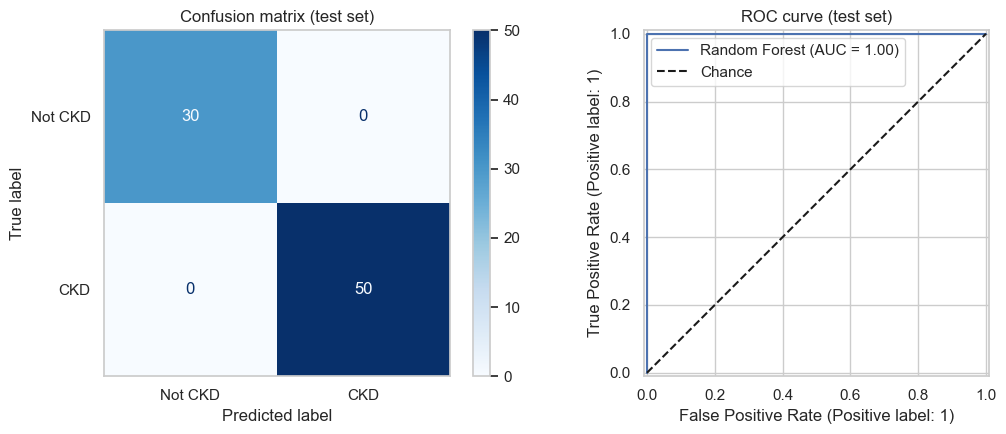

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Not CKD", "CKD"], cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].set_title("ROC curve (test set)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [102]:
# With only 80 test patients, a single AUC is uncertain.
# A bootstrap gives a 95% confidence interval by resampling the test set.
rng = np.random.default_rng(RANDOM_STATE)
y_true = y_test.to_numpy()
boot_aucs = []

for _ in range(1000):
    idx = rng.integers(0, len(y_true), len(y_true))
    if len(np.unique(y_true[idx])) < 2:       # need both classes to compute AUC
        continue
    boot_aucs.append(roc_auc_score(y_true[idx], y_prob[idx]))

low, high = np.percentile(boot_aucs, [2.5, 97.5])
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}  (95% bootstrap CI: {low:.3f} to {high:.3f})")

Test ROC-AUC: 1.000  (95% bootstrap CI: 1.000 to 1.000)


###### **See, the ROC-AUC is very consistent and and it's tightly 1 regardless of the sampling combination**

#### **Which features drive the predictions?**
---

**Permutation importance:** shuffle one feature at a time on the test set and measure how much the model gets worse
(here, how much the log-loss increases). A bigger increase means the model relies more on that feature.

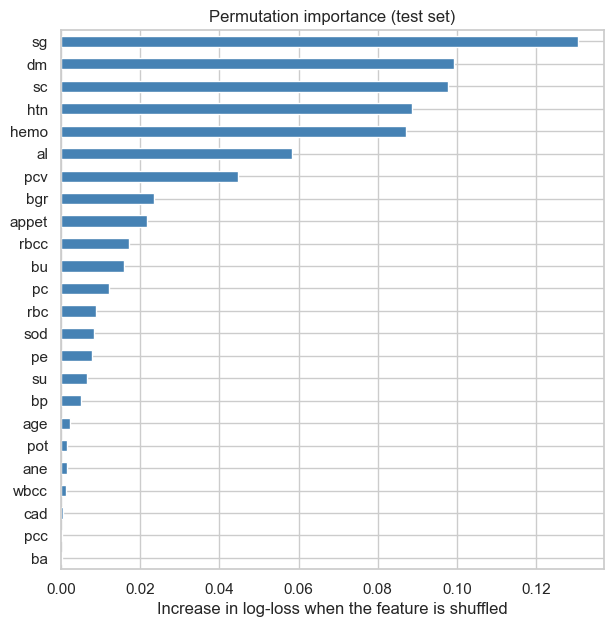

In [103]:
perm = permutation_importance(final_model, X_test, y_test, scoring="neg_log_loss",
                              n_repeats=20, random_state=RANDOM_STATE)

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind="barh", figsize=(7, 7), color="steelblue")
plt.xlabel("Increase in log-loss when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.show()

#### **10. Robustness check: remove the most "obvious" kidney markers**
---

Serum creatinine (`sc`) and blood urea (`bu`) are the direct markers used to define reduced kidney function, so a model could look
impressive simply by rediscovering the diagnosis. To test this, I re-run cross-validation **without these two features**.
If performance stays high, the model is also using other signals (haemoglobin, urine albumin, specific gravity, and so on).

In [104]:
drop_cols = ["sc", "bu"]
numeric_reduced = [c for c in numeric_cols if c not in drop_cols]

preprocessor_reduced = make_column_transformer(
    (numeric_pipe, numeric_reduced),
    (categorical_pipe, categorical_cols),
)
# clone(final_model[-1]) = same tuned classifier settings, untrained
model_reduced = make_pipeline(preprocessor_reduced, clone(final_model[-1]))

scores_full = cross_validate(final_model, X_train, y_train, cv=cv, scoring=scoring)
scores_reduced = cross_validate(model_reduced, X_train, y_train, cv=cv, scoring=scoring)

pd.DataFrame({
    "All features": {m: scores_full[f"test_{m}"].mean() for m in scoring},
    "Without sc and bu": {m: scores_reduced[f"test_{m}"].mean() for m in scoring},
}).T.round(3)

,roc_auc,recall,precision,f1,accuracy
All features,0.999,0.998,0.99,0.994,0.993
Without sc and bu,0.999,0.995,0.99,0.993,0.991


To test whether the model simply reproduces the biochemical definition of CKD, cross-validation was repeated without serum creatinine and blood urea.
The model's performance was essentially unchanged (ROC-AUC 0.999 in both; recall 0.998 vs 0.995), a difference well within fold-to-fold variation.
The model therefore draws on other signals, chiefly the red cell indices, urine specific gravity and albumin, and comorbidities.
This should not be read as evidence of early-disease detection: in this dataset CKD patients differ from controls on many measures simultaneously.

In [105]:
# Save the trained model so it can be reused without retraining
joblib.dump(final_model, "ckd_model.joblib")
print("Saved: ckd_model.joblib")

Saved: ckd_model.joblib


In [106]:
# Results summary (auto-generated from the numbers above)
test_recall = ((y_pred == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
print(f"Selected model        : {best_name}")
print(f"Cross-validated AUC   : {grid.best_score_:.3f}")
print(f"Test ROC-AUC          : {roc_auc_score(y_test, y_prob):.3f}  (95% CI {low:.3f} to {high:.3f})")
print(f"Test recall (CKD)     : {test_recall:.3f}")
print(f"CV AUC without sc, bu : {scores_reduced['test_roc_auc'].mean():.3f}")

Selected model        : Random Forest
Cross-validated AUC   : 1.000
Test ROC-AUC          : 1.000  (95% CI 1.000 to 1.000)
Test recall (CKD)     : 1.000
CV AUC without sc, bu : 0.999


#### **11.0 Conclusion**
---
I built a model to tell CKD patients from non-CKD patients using routine urine, blood and clinical results. The data needed some cleaning first: tabs and stray spaces in the text columns, ? for missing values, and a few lab values that no living patient could have, like potassium of 47. I left the extreme creatinine values alone, because very high creatinine does happen in real patients.

Random Forest, Logistic Regression and Gradient Boosting all did very well in cross-validation, and the gaps between them were tiny. ROC-AUC was close to 1.0 for all three, so it couldn’t separate them. I ended up choosing on recall, because in the clinical settings and specifically with CKD, missing a real patient is more serious than falsely identifying one. Random Forest came out on top there (recall 0.998, precision 0.990).On the test data the modely perfectly classified CKD and not CKD patients.

I wouldn’t read too much into that. The test set is only about 80 patients, so “no misses” still leaves a lot of room for error.The CKD patients in this data are also very different from the controls, and the healthy group had almost no abnormal findings at all.I am a Medical laboratory scientist and trust me, real screening comes harder than this.You won't alwayss find such easy split in biochemical and other parameters between normal and diseased subject that way. 

Two checks made me more comfortable with the model:

Without creatinine and urea, performance barely moved. So the model isn’t just repeating the definition of CKD back at us. Haemoglobin, PCV, RBC count, specific gravity and urine albumin carry a lot on their own.
Collinearity between the red cell measures was moderate (VIF about 4.5 to 5.4). That makes sense, since PCV is roughly three times haemoglobin. Because I care about prediction here and not about reading coefficients, I kept all of them.

#### **12.0 Limitations**
---
400 patients from one hospital, with no outside validation.
Heavy missing data, filled with the median or most common value. In real hospitals a test is often missing for some few reasons and that can mean something.
Hyperparameters were tuned only for the model that won the comparison. With the three models this close, another one might have won after tuning.
It isn’t validated for clinical use. This is a learning project.

#### **What’s next**
---
My goal is to work with richer data from Ghana, and this notebook is the base for that. I’ll keep changing it. The main thing I want to try is getting the same performance with fewer features, since a model that needs a short list of cheap tests is far more useful in a district hospital than one that needs thirty results. I also want to look at missing-value indicators, threshold tuning for recall, and checking whether the model holds up on a different population.